# Where Does the Retina Show Its Age?
## Interpretable retinal age prediction and the "retinal age gap" as a marker of systemic health

**Author:** Sadaf Zehra · pilot study

**Background.** Deep networks can estimate a person's age from a colour fundus photograph. The difference between predicted and real age (the *retinal age gap*) has been linked in large cohorts to systemic conditions such as diabetes, hypertension and cardiovascular risk. Most of these models are black boxes, so a clinician cannot see *which* part of the retina makes someone "look older".

**Questions**
1. How well can a ResNet-50 predict age from healthy fundus images (ODIR-5K)?
2. Is the age gap larger in eyes with signs of systemic disease (diabetic and hypertensive retinopathy) than in healthy eyes, after correcting for regression-to-the-mean, age and sex? Does it grow with DR severity?
3. **Where** does the model read age from? We compare two models:
   - **ResNet-50 + Grad-CAM** (post-hoc)
   - **Evidence-map regressor** (inherently interpretable): a 1×1 conv gives an "age map", and the predicted age is exactly `mean_age + std × spatial mean(map)`. So every region's contribution can be read **in years**.
   Attribution is split into anatomical regions found automatically (optic disc, macula, vessels, periphery, other retina, background).
4. Does the reading pattern change between young and old people? (population-average maps, aligned by optic-disc side)
5. Are the explanations faithful? (deletion test)

Runs on **Kaggle Notebooks** (recommended) or Google Colab, on a free T4 GPU. Data is downloaded automatically with `kagglehub` (mixed precision, cached images, checkpoints saved).

## How to use

**On Kaggle (recommended, no key needed)**
1. Phone-verify your Kaggle account once (Settings → Phone Verification).
2. New Notebook → *File → Import Notebook* → this file.
3. Right panel → Session options: *Accelerator* = **GPU T4 x2**, *Internet* = **On**.
4. First *Run All* with `DEMO_MODE = True` (synthetic data, about 10 minutes).
5. Set `DEMO_MODE = False`, then **Save Version → Save & Run All (Commit)**. ODIR-5K downloads automatically; results appear in the notebook's *Output* (`/kaggle/working/fundus_xai/age_outputs/`).

**On Colab** the same notebook works: results go to `MyDrive/fundus_xai/`. Public datasets usually download without a key; if Kaggle asks for one, add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's 🔑 Secrets.

In [2]:
# --- General imports (all pre-installed on Kaggle and Colab) ---
import os, re, sys, glob, json, math, random, time, shutil, zipfile, warnings, subprocess
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, ndimage
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from skimage.filters import frangi
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except ImportError:
    display = print

def walk_files(root, name_pattern="*"):
    """Recursive file search that also enters symlinked folders (Kaggle mounts inputs this way)."""
    import fnmatch
    for dirpath, _, files in os.walk(str(root), followlinks=True):
        for f in files:
            if fnmatch.fnmatch(f, name_pattern):
                yield Path(dirpath) / f

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [3]:
# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU nahi mila. Kaggle: Session options > Accelerator > GPU T4 x2 | Colab: Runtime > Change runtime type > T4 GPU")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
torch.backends.cudnn.benchmark = True
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda
GPU: Tesla T4


In [4]:
# ======================= CONFIG =======================
DEMO_MODE = False        # pehle True: synthetic data par poora pipeline test. Phir False for the real study.
FORCE_RETRAIN = False

CFG = dict(
    img_size=384,
    batch_size=16,
    epochs=15,
    lr=3e-4,
    weight_decay=1e-4,
    warmup_epochs=1,
    patience=4,              # early stopping on validation MAE
    num_workers=min(4, os.cpu_count() or 2),
    dilate_layer4=True,      # 24x24 maps at 384 px
    evidence_l1=1e-4,
    min_age=18, max_age=90,
    val_frac=0.15, test_frac=0.20,   # patient-level split of HEALTHY patients
    seed=42,
    fov_thresh=12,
    n_bootstrap=1000,
    n_region=400,            # images used for anatomical region analysis
    n_deletion=150,
    pool=8,
)
if DEMO_MODE:
    CFG.update(img_size=224, epochs=4, patience=2, n_bootstrap=200, n_region=60, n_deletion=30, pool=4)

# --- Paths: Kaggle (/kaggle/working), Colab (Google Drive) or local ---
ON_KAGGLE = Path("/kaggle/input").exists()
IN_COLAB = False
if ON_KAGGLE:
    BASE = Path("/kaggle/working/fundus_xai")   # saved as notebook Output
    RAW = Path("/tmp/raw")                       # raw data stays out of the Output
else:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/fundus_xai")
        RAW = Path("/content/raw")
        IN_COLAB = True
    except ImportError:
        BASE = Path("./fundus_xai")
        RAW = BASE / "raw"

CACHE = BASE / f"age_cache_{'demo_' if DEMO_MODE else ''}{CFG['img_size']}"
OUT = BASE / ("age_outputs_demo" if DEMO_MODE else "age_outputs")
for p in [RAW, CACHE, OUT]:
    p.mkdir(parents=True, exist_ok=True)

ODIR_ROOT = None                # set by the Data cell (kagglehub download folder)

# Diagnostic-keyword rules (per eye). Order = priority for the "main" group of an eye.
GROUP_RULES = [
    ("Diabetic retinopathy",    ["proliferative", "diabetic retinopathy"]),
    ("Hypertensive retinopathy", ["hypertensive"]),
    ("Glaucoma",                ["glaucoma"]),
    ("AMD",                     ["macular degeneration"]),
    ("Drusen",                  ["drusen"]),
    ("Cataract",                ["cataract"]),
    ("Myopia",                  ["myopi"]),
]
EXCLUDE_KEYWORDS = ["low image quality", "no fundus image", "image offset",
                    "photographically invisible", "anterior segment", "lens dust"]
DR_SEVERITY = [("proliferative diabetic", 4), ("severe nonproliferative", 3), ("severe non proliferative", 3),
               ("moderate non proliferative", 2), ("moderate nonproliferative", 2),
               ("mild nonproliferative", 1), ("mild non proliferative", 1)]

print("BASE :", BASE, "\nCACHE:", CACHE, "\nOUT  :", OUT)

BASE : /kaggle/working/fundus_xai 
CACHE: /kaggle/working/fundus_xai/age_cache_384 
OUT  : /kaggle/working/fundus_xai/age_outputs


## Data

**ODIR-5K** (Ocular Disease Intelligent Recognition): about 5,000 patients from hospitals in China, with age, sex, left and right colour fundus photos from several cameras (Canon, Zeiss, Kowa), and doctors' diagnostic keywords per eye. Please follow the dataset's terms and cite it.

The cell below gets it in this order:
1. already attached to the Kaggle notebook (*Add Input*), if you did that;
2. otherwise downloaded automatically with `kagglehub` from https://www.kaggle.com/datasets/andrewmvd/ocular-disease-recognition-odir5k (public dataset: no key needed inside Kaggle);
3. once the images are cached, later runs in the same place do not download again.

The loader looks for any `.xlsx` / `.csv` table with the columns `Patient Age`, `Patient Sex`, `Left-Fundus`, `Right-Fundus`, `Left-Diagnostic Keywords`, `Right-Diagnostic Keywords`, and finds the image files recursively.

**Design choices**
- The age model is trained **only on patients whose both eyes are "normal fundus"**, split by patient (no eye of a test patient is seen in training).
- Eyes with disease keywords are used only for the age-gap analysis, and only from patients not used in training/validation.
- Images with quality problems (`low image quality`, `lens dust`, `no fundus image`, ...) are removed.

In [5]:
# --- Data: attached Kaggle input, or automatic kagglehub download ---
ODIR_SLUG = "andrewmvd/ocular-disease-recognition-odir5k"
ODIR_INDEX = CACHE / "_odir_index.csv"
INPUT = Path("/kaggle/input")

def show_tree(root, depth=3, max_items=8, _level=0):
    root = Path(root)
    if _level == 0:
        print(root)
    if _level >= depth or not root.is_dir():
        return
    items = sorted(root.iterdir())
    for d in [p for p in items if p.is_dir()][:max_items]:
        print("    " * (_level + 1) + f"[{d.name}]")
        show_tree(d, depth, max_items, _level + 1)
    files = [p for p in items if p.is_file()]
    if files:
        print("    " * (_level + 1) + f"{len(files)} files: {', '.join(f.name for f in files[:4])}{' ...' if len(files) > 4 else ''}")

def looks_like_odir(base):
    return any(True for _ in walk_files(base, "full_df.csv")) or any(True for _ in walk_files(base, "*ODIR*.xlsx"))

def kh_get(handle):
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
        import kagglehub
    if IN_COLAB:                                    # optional: Colab secrets, only used if present
        try:
            from google.colab import userdata
            u, k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
            if u and k:
                os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = u, k
        except Exception:
            pass
    try:
        print(f"[kagglehub] downloading {handle} ... (first time can take a few minutes)")
        path = Path(kagglehub.dataset_download(handle))
        print(f"[kagglehub] {handle} -> {path}")
    except Exception as e:
        print(f"[kagglehub] {handle} failed: {str(e)[:300]}")
        return None
    if any(True for _ in walk_files(path, "*.zip")):  # some downloads stay zipped -> extract to the raw folder
        out = RAW / handle.replace("/", "_")
        if not out.exists():
            for f in walk_files(path):
                rel = f.relative_to(path)
                if f.suffix.lower() == ".zip":
                    print("   extracting", f.name, "...")
                    with zipfile.ZipFile(f) as zf:
                        zf.extractall(out / rel.parent)
                else:
                    (out / rel).parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(f, out / rel)
        return out
    return path

if not DEMO_MODE and not ODIR_INDEX.exists():
    if INPUT.exists() and looks_like_odir(INPUT):
        ODIR_ROOT = INPUT
        print("Using ODIR attached in /kaggle/input")
    else:
        ODIR_ROOT = kh_get(ODIR_SLUG)
    if ODIR_ROOT is None:
        print("[error] ODIR could not be downloaded. Check that Internet is ON (Kaggle: Session options), then run again.")
    else:
        show_tree(ODIR_ROOT, depth=2)
elif ODIR_INDEX.exists():
    print("ODIR images already cached -> no download needed:", ODIR_INDEX)

[kagglehub] downloading andrewmvd/ocular-disease-recognition-odir5k ... (first time can take a few minutes)
Using Colab cache for faster access to the 'ocular-disease-recognition-odir5k' dataset.
[kagglehub] andrewmvd/ocular-disease-recognition-odir5k -> /kaggle/input/ocular-disease-recognition-odir5k
/kaggle/input/ocular-disease-recognition-odir5k
    [ODIR-5K]
        [ODIR-5K]
    [preprocessed_images]
        6392 files: 0_left.jpg, 0_right.jpg, 1005_right.jpg, 1006_left.jpg ...
    1 files: full_df.csv


In [6]:
# --- DEMO data: synthetic ODIR-like patients ---
# Age effects built in: thinner vessels, yellower/darker lens tint, macular drusen after ~60.
# Disease effects: DR = red/yellow lesions; hypertensive = extra vessel narrowing (should look OLDER);
# glaucoma = large pale cup; cataract = haze/blur.
def _demo_eye(rng, age, keyword, size, flip):
    H = W = size
    yy, xx = np.mgrid[0:H, 0:W]
    cy, cx, R = H / 2, W / 2, size * 0.44
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2) / R
    a = (age - 20) / 65.0                                    # 0 (young) .. 1 (old)
    tint = np.array([1.0, 0.55 - 0.12 * a, 0.35 - 0.15 * a]) * (1.0 - 0.18 * a)
    base = np.clip(1.0 - 0.45 * r ** 2, 0, 1) * (r < 1)
    img = Image.fromarray((np.stack([base * t for t in tint], -1) * 255).clip(0, 255).astype(np.uint8))
    d = ImageDraw.Draw(img)
    ox, oy, orad = cx + R * 0.45, cy + rng.uniform(-8, 8), R * 0.12   # optic disc on the right
    d.ellipse([ox - orad, oy - orad, ox + orad, oy + orad], fill=(250, 215, 160))
    if "glaucoma" in keyword:
        d.ellipse([ox - orad * 0.75, oy - orad * 0.75, ox + orad * 0.75, oy + orad * 0.75], fill=(255, 245, 225))
    width = size / 70 * (1.25 - 0.55 * a) * (0.6 if "hypertensive" in keyword else 1.0)
    for _ in range(8):
        ang = rng.uniform(0, 2 * np.pi); pts = [(ox, oy)]
        for _k in range(7):
            ang += rng.uniform(-0.3, 0.3)
            pts.append((pts[-1][0] + np.cos(ang) * R * 0.14, pts[-1][1] + np.sin(ang) * R * 0.14))
        d.line(pts, fill=(115, 22, 18), width=max(1, int(round(width))))
    mx, my = cx - R * 0.25, cy                               # macula (~2.5 disc diameters from the disc)
    d.ellipse([mx - R * 0.1, my - R * 0.1, mx + R * 0.1, my + R * 0.1], fill=tuple(int(v * 150) for v in tint))
    if age > 58:
        for _ in range(int((age - 58) / 4)):
            s, t = rng.uniform(0, 2 * np.pi), R * 0.16 * np.sqrt(rng.uniform())
            d.ellipse([mx + t * np.cos(s) - 2, my + t * np.sin(s) - 2, mx + t * np.cos(s) + 2, my + t * np.sin(s) + 2],
                      fill=(240, 220, 140))
    if "retinopathy" in keyword and "hypertensive" not in keyword:
        for _ in range(int(rng.integers(6, 20))):
            s, t = rng.uniform(0, 2 * np.pi), R * np.sqrt(rng.uniform(0.02, 0.8))
            lx, ly, z = cx + t * np.cos(s), cy + t * np.sin(s), rng.uniform(2, 5)
            d.ellipse([lx - z, ly - z, lx + z, ly + z], fill=(140, 10, 10) if rng.random() < 0.6 else (255, 235, 120))
    if "cataract" in keyword:
        img = Image.blend(img.filter(ImageFilter.GaussianBlur(3)), Image.new("RGB", img.size, (200, 170, 140)), 0.25)
        img = Image.fromarray((np.asarray(img) * (r < 1)[..., None]).astype(np.uint8))
    if flip:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    return img

def make_demo_odir(root, n_patients=420, size=320, seed=0):
    root = Path(root); img_dir = root / "Training Images"; img_dir.mkdir(parents=True, exist_ok=True)
    kw = {"N": "normal fundus", "D": "moderate non proliferative retinopathy",
          "H": "hypertensive retinopathy", "G": "glaucoma", "C": "cataract"}
    rows = []
    for pid in range(n_patients):
        prng = np.random.default_rng([seed, pid])          # per-patient RNG: labels never depend on cached files
        age = int(np.clip(prng.normal(56, 14), 20, 88)); sex = prng.choice(["Male", "Female"])
        cond = prng.choice(["N", "D", "H", "G", "C"], p=[0.6, 0.15, 0.1, 0.075, 0.075])
        lk = kw[cond]; rk = kw[cond] if prng.random() < 0.7 else "normal fundus"
        for e, (eye, k) in enumerate([("left", lk), ("right", rk)]):
            p = img_dir / f"{pid}_{eye}.jpg"
            if not p.exists():
                _demo_eye(np.random.default_rng([seed, pid, e]), age, k, size, flip=(eye == "left")).save(p, quality=95)
        rows.append({"ID": pid, "Patient Age": age, "Patient Sex": sex,
                     "Left-Fundus": f"{pid}_left.jpg", "Right-Fundus": f"{pid}_right.jpg",
                     "Left-Diagnostic Keywords": lk, "Right-Diagnostic Keywords": rk})
    pd.DataFrame(rows).to_csv(root / "demo_annotations.csv", index=False)
    return root

if DEMO_MODE:
    ODIR_ROOT = make_demo_odir(RAW / "demo_odir")
    print("Demo ODIR created at", ODIR_ROOT)

In [7]:
# --- Parse ODIR: one row per EYE ---
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
NEEDED = ["Patient Age", "Patient Sex", "Left-Fundus", "Right-Fundus",
          "Left-Diagnostic Keywords", "Right-Diagnostic Keywords"]

def find_annotation_table(root):
    cands = sorted(walk_files(root, "*.xlsx")) + sorted(walk_files(root, "*.csv"))
    cands = sorted(cands, key=lambda c: (c.name != "full_df.csv", "annotation" not in c.name.lower()))
    for c in cands:
        try:
            df = pd.read_excel(c) if c.suffix == ".xlsx" else pd.read_csv(c)
        except Exception:
            continue
        df.columns = [str(x).strip() for x in df.columns]
        if all(n in df.columns for n in NEEDED):
            print("Annotation table:", c)
            return df
    raise FileNotFoundError("No annotation table with ODIR columns found. Run show_tree(RAW) and check.")

def split_keywords(s):
    return [k.strip().lower() for k in re.split(r"[，,;]", str(s)) if k.strip()]

def eye_groups(kws):
    groups = [g for g, pats in GROUP_RULES if any(p in k for k in kws for p in pats)]
    return groups

def dr_severity(kws):
    sev = 0
    for k in kws:
        for pat, v in DR_SEVERITY:
            if pat in k:
                sev = max(sev, v)
    return sev

def build_image_index(root):
    index = {}
    for p in sorted(walk_files(root)):
        if p.suffix.lower() in IMG_EXT:
            index.setdefault(p.stem.lower(), []).append(p)
    # prefer original images over pre-processed copies
    return {k: sorted(v, key=lambda q: ("training images" not in str(q).lower(), len(str(q))))[0]
            for k, v in index.items()}

def load_odir(root):
    ann = find_annotation_table(root)
    if "ID" not in ann.columns:
        ann["ID"] = ann["Left-Fundus"].astype(str).str.extract(r"(\d+)")[0]
    # Kaggle's full_df.csv has one row per image -> keep one row per patient
    ann = ann.drop_duplicates(subset=["Left-Fundus", "Right-Fundus"])
    index = build_image_index(root)
    rows = []
    for rec in ann.to_dict("records"):
        for eye in ["Left", "Right"]:
            fname = str(rec[f"{eye}-Fundus"])
            kws = split_keywords(rec[f"{eye}-Diagnostic Keywords"])
            rows.append(dict(patient=str(rec["ID"]), eye=eye.lower(), file=fname,
                             key=Path(fname).stem.lower(), age=rec["Patient Age"],
                             sex=str(rec["Patient Sex"]).strip().lower(), keywords="; ".join(kws),
                             normal=kws == ["normal fundus"],
                             excluded=any(e in k for k in kws for e in EXCLUDE_KEYWORDS),
                             groups="|".join(eye_groups(kws)), dr_severity=dr_severity(kws)))
    df = pd.DataFrame(rows)
    df["path"] = df["key"].map(index)
    n0 = len(df)
    df = df.dropna(subset=["path"])
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df = df[(df.age >= CFG["min_age"]) & (df.age <= CFG["max_age"]) & ~df.excluded].reset_index(drop=True)
    df["male"] = (df["sex"].str.startswith("m")).astype(int)
    pat_normal = df.groupby("patient")["normal"].transform("all") & (df.groupby("patient")["eye"].transform("nunique") == 2)
    df["healthy_patient"] = pat_normal
    print(f"eyes with image + valid age + good quality: {len(df)} (from {n0})")
    print(f"healthy patients (both eyes normal): {df.loc[df.healthy_patient, 'patient'].nunique()}")
    g = df["groups"].str.split("|").explode()
    print("eyes per group:", g[g != ""].value_counts().to_dict())
    return df

if ODIR_INDEX.exists():
    ODIR = None            # loaded from the cache index in the next cell (no raw data needed)
    print("Using cached ODIR index:", ODIR_INDEX)
else:
    assert ODIR_ROOT is not None, "ODIR not available: see the message of the Data cell above."
    ODIR = load_odir(ODIR_ROOT)
    display(ODIR.head(3))

Annotation table: /kaggle/input/ocular-disease-recognition-odir5k/full_df.csv
eyes with image + valid age + good quality: 6426 (from 6716)
healthy patients (both eyes normal): 999
eyes per group: {'Diabetic retinopathy': 1747, 'Glaucoma': 310, 'Cataract': 287, 'AMD': 277, 'Myopia': 232, 'Hypertensive retinopathy': 193, 'Drusen': 160}


,patient,eye,file,key,age,sex,keywords,normal,excluded,groups,dr_severity,path,male,healthy_patient
0,0,left,0_left.jpg,0_left,69,female,cataract,False,False,Cataract,0,/kaggle/input/ocular-disease-recognition-odir5...,0,False
1,0,right,0_right.jpg,0_right,69,female,normal fundus,True,False,,0,/kaggle/input/ocular-disease-recognition-odir5...,0,False
2,1,left,1_left.jpg,1_left,57,male,normal fundus,True,False,,0,/kaggle/input/ocular-disease-recognition-odir5...,1,True


In [8]:
# --- Preprocessing + cache (crop black border, pad to square, resize) ---
def crop_box(img, thr):
    small = img.convert("L").copy()
    small.thumbnail((600, 600))
    a = np.asarray(small) > thr
    rows, cols = np.where(a.any(1))[0], np.where(a.any(0))[0]
    if len(rows) < 10 or len(cols) < 10:
        return (0, 0, img.width, img.height)
    sx, sy = img.width / small.width, img.height / small.height
    return (int(cols[0] * sx), int(rows[0] * sy),
            min(img.width, int((cols[-1] + 1) * sx)), min(img.height, int((rows[-1] + 1) * sy)))

def square_resize(img, box, size, resample):
    crop = img.crop(box)
    w, h = crop.size
    s = max(w, h)
    canvas = Image.new(crop.mode, (s, s), 0)
    canvas.paste(crop, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), resample)

def _cache_one(args):
    src, dst, size, thr = args
    if Path(dst).exists():
        return True
    try:
        img = Image.open(src).convert("RGB")
        square_resize(img, crop_box(img, thr), size, Image.BICUBIC).save(dst, quality=95)
        return True
    except Exception as e:
        print("[error]", src, e)
        return False

def cache_images(df, workers=8):
    CACHE.mkdir(parents=True, exist_ok=True)
    df = df.copy()
    df["cpath"] = [str(CACHE / f"{k}.jpg") for k in df["key"]]
    todo = [(str(s), d, CFG["img_size"], CFG["fov_thresh"]) for s, d in zip(df["path"], df["cpath"]) if not Path(d).exists()]
    if todo:
        with ThreadPoolExecutor(workers) as ex:
            list(tqdm(ex.map(_cache_one, todo), total=len(todo), desc="caching"))
    return df[df["cpath"].map(lambda p: Path(p).exists())].reset_index(drop=True)

if ODIR is None:
    ODIR = pd.read_csv(ODIR_INDEX, dtype={"patient": str, "key": str, "file": str},
                       keep_default_na=False, na_values={"age": [""]})
    for c in ["normal", "excluded", "healthy_patient"]:
        ODIR[c] = ODIR[c].astype(str).str.lower().eq("true")
else:
    ODIR = cache_images(ODIR)
    ODIR.drop(columns=["path"]).to_csv(ODIR_INDEX, index=False)
if str(CACHE).startswith("/content/drive"):          # read from local disk during training (much faster)
    LOCAL_CACHE = Path("/content/cache_local") / CACHE.name
    print("Copying cache to local disk ...")
    shutil.copytree(CACHE, LOCAL_CACHE, dirs_exist_ok=True)
    ODIR["cpath"] = ODIR["cpath"].str.replace(str(CACHE), str(LOCAL_CACHE), regex=False)
print("cached eyes:", len(ODIR))

caching:   0%|          | 0/6426 [00:00<?, ?it/s]

cached eyes: 6426


In [9]:
# --- Patient-level split of HEALTHY patients; disease eyes from patients never used for training ---
healthy_pat = ODIR.loc[ODIR.healthy_patient, ["patient", "age"]].groupby("patient")["age"].first()
age_bins = pd.qcut(healthy_pat, 5, labels=False, duplicates="drop")
tr_p, te_p = train_test_split(healthy_pat.index, test_size=CFG["test_frac"], stratify=age_bins, random_state=CFG["seed"])
tr_p, va_p = train_test_split(tr_p, test_size=CFG["val_frac"] / (1 - CFG["test_frac"]),
                              stratify=age_bins.loc[tr_p], random_state=CFG["seed"])
SPLITS = {
    "train": ODIR[ODIR.patient.isin(tr_p)].reset_index(drop=True),
    "val": ODIR[ODIR.patient.isin(va_p)].reset_index(drop=True),
    "test": ODIR[ODIR.patient.isin(te_p)].reset_index(drop=True),
}
used = set(tr_p) | set(va_p)
DISEASE = ODIR[(~ODIR.patient.isin(used)) & (ODIR.groups != "")].reset_index(drop=True)
AGE_MEAN, AGE_STD = float(SPLITS["train"].age.mean()), float(SPLITS["train"].age.std())
print({k: f"{len(v)} eyes / {v.patient.nunique()} patients" for k, v in SPLITS.items()})
print("disease eyes for gap analysis:", len(DISEASE), "| age mean/std (train):", round(AGE_MEAN, 1), round(AGE_STD, 1))

{'train': '1298 eyes / 649 patients', 'val': '300 eyes / 150 patients', 'test': '400 eyes / 200 patients'}
disease eyes for gap analysis: 3012 | age mean/std (train): 56.8 11.1


In [10]:
# --- Numpy helpers: FOV, anatomy masks, region statistics, statistics ---
def load_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))

def fov_mask(arr, thr=None):
    thr = CFG["fov_thresh"] if thr is None else thr
    m = arr.astype(np.float32).mean(-1) > thr
    m = ndimage.binary_opening(m, iterations=2)
    lab, n = ndimage.label(m)
    if n > 1:
        sizes = ndimage.sum(m, lab, range(1, n + 1))
        m = lab == (int(np.argmax(sizes)) + 1)
    return ndimage.binary_fill_holes(m)

REGIONS = ["optic_disc", "macula", "vessels", "periphery", "other_retina", "background"]

def anatomy_masks(arr, fov=None):
    """Automatic, approximate anatomy: optic disc (brightest blob), macula (darkest spot ~2.5 disc
    diameters from the disc), vessels (Frangi filter on the green channel), periphery (outer ring).
    Regions are mutually exclusive (priority in REGIONS order)."""
    H, W = arr.shape[:2]
    fov = fov_mask(arr) if fov is None else fov
    yy, xx = np.mgrid[0:H, 0:W]
    ys, xs = np.nonzero(fov)
    cy, cx = ys.mean(), xs.mean()
    R = math.sqrt(fov.sum() / math.pi)
    inner = ndimage.binary_erosion(fov, iterations=max(2, H // 40))
    gray = arr.astype(np.float64).mean(-1)
    green = arr[..., 1].astype(np.float64)
    sm = ndimage.gaussian_filter(gray, sigma=H / 50)
    sm[~inner] = -np.inf
    oy, ox = np.unravel_index(np.argmax(sm), sm.shape)
    od_r = 0.15 * R
    DD = 2 * od_r
    d_od = np.hypot(yy - oy, xx - ox)
    smg = ndimage.gaussian_filter(green, sigma=H / 40)
    toward_centre = (xx - ox) * (cx - ox) > 0                 # macula lies on the centre side of the disc
    near_centre = np.hypot(yy - cy, xx - cx) < 0.6 * R
    cand = inner & toward_centre & near_centre & (d_od > 1.8 * DD) & (d_od < 3.2 * DD) & (np.abs(yy - oy) < 1.0 * DD)
    if cand.any():
        v = np.where(cand, smg, np.inf)
        my, mx = np.unravel_index(np.argmin(v), v.shape)
    else:
        my, mx = oy, 2 * cx - ox
    od = (d_od < od_r) & fov
    mac = (np.hypot(yy - my, xx - mx) < 1.5 * od_r) & fov & ~od
    vs = frangi(green / 255.0, sigmas=range(1, max(2, H // 96) + 1), black_ridges=True)
    vs[~inner] = 0
    ves = (vs > np.quantile(vs[inner], 0.88)) & inner & ~od & ~mac
    per = fov & (np.hypot(yy - cy, xx - cx) > 0.8 * R) & ~od & ~mac & ~ves
    other = fov & ~od & ~mac & ~ves & ~per
    masks = dict(optic_disc=od, macula=mac, vessels=ves, periphery=per, other_retina=other, background=~fov)
    return masks, (int(ox), int(oy)), (int(mx), int(my))

def region_stats(signed_map, masks, years_per_unit=None):
    """Share of |attribution| per region, area share, lift; for the evidence model also the exact
    contribution of each region in years (map mean == prediction)."""
    a = np.abs(signed_map).astype(np.float64)
    tot = a.sum() + 1e-12
    n = signed_map.size
    out = {}
    for k in REGIONS:
        m = masks[k]
        share, area = float(a[m].sum() / tot), float(m.mean())
        out[f"{k}_share"] = share
        out[f"{k}_area"] = area
        out[f"{k}_lift"] = share / (area + 1e-12)
        if years_per_unit is not None:
            out[f"{k}_years"] = float(signed_map[m].sum() / n * years_per_unit)
    return out

def bias_fit(age, gap):
    """Regression-to-the-mean correction: gap ~ a*age + b, fitted on healthy validation data."""
    a, b = np.polyfit(np.asarray(age, float), np.asarray(gap, float), 1)
    return float(a), float(b)

def ols(y, X, names):
    """Ordinary least squares with standard errors and two-sided p-values."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = max(len(y) - X.shape[1], 1)
    s2 = resid @ resid / dof
    cov = s2 * np.linalg.pinv(X.T @ X)
    se = np.sqrt(np.diag(cov))
    t = beta / (se + 1e-12)
    p = 2 * stats.t.sf(np.abs(t), dof)
    return pd.DataFrame(dict(coef=beta, se=se, t=t, p=p), index=names)

def bootstrap_mean_ci(x, n=None, seed=0):
    n = n or CFG["n_bootstrap"]
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(np.mean(x)) if len(x) else np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    m = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / max(len(a) + len(b) - 2, 1))
    return float((a.mean() - b.mean()) / (sp + 1e-12))

In [11]:
# --- Dataset ---
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
# Mild colour augmentation only: lens tint carries real age information.
TRAIN_AUG = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.1, contrast=0.1),
])

def to_tensor(arr):
    return torch.from_numpy(np.ascontiguousarray(arr)).permute(2, 0, 1).float() / 255.0

def normalize(x):
    return (x - MEAN.to(x.device)) / STD.to(x.device)

class AgeDS(torch.utils.data.Dataset):
    def __init__(self, df, train=False):
        self.df, self.train = df.reset_index(drop=True), train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        arr = load_rgb(r["cpath"])
        x = to_tensor(arr)
        if self.train:
            x = TRAIN_AUG(x)
        y = torch.tensor((float(r["age"]) - AGE_MEAN) / AGE_STD, dtype=torch.float32)
        return normalize(x), y, i

def make_loader(df, train=False):
    return torch.utils.data.DataLoader(AgeDS(df, train), batch_size=CFG["batch_size"], shuffle=train,
                                       num_workers=CFG["num_workers"], pin_memory=DEVICE == "cuda", drop_last=train)

In [12]:
# --- Models: both predict standardized age; explain() returns age in years + a signed map ---
def _resnet50():
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2,
                                    replace_stride_with_dilation=[False, False, CFG["dilate_layer4"]])
    return nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)

class GradCAMReg(nn.Module):
    kind = "gradcam"
    def __init__(self):
        super().__init__()
        self.body = _resnet50()
        self.fc = nn.Linear(2048, 1)
    def head(self, A):
        return self.fc(A.mean((2, 3)))[:, 0]
    def forward(self, x):
        return self.head(self.body(x)), None

class EvidenceReg(nn.Module):
    """Age map: predicted (standardized) age is exactly the spatial mean of the map."""
    kind = "evidence"
    def __init__(self):
        super().__init__()
        self.body = _resnet50()
        self.drop = nn.Dropout2d(0.1)
        self.cls = nn.Conv2d(2048, 1, 1)
    def forward(self, x):
        M = self.cls(self.drop(self.body(x)))[:, 0]
        return M.mean((1, 2)), M

MODELS = {"gradcam": GradCAMReg, "evidence": EvidenceReg}
NAME = {"gradcam": "ResNet-50 + Grad-CAM", "evidence": "Evidence-map regressor"}

def explain(model, x):
    """Returns (predicted age in years [B], signed map [B,H,W]).
    evidence: map in years relative to the training mean (its pixel mean = predicted age - mean age).
    gradcam : signed Grad-CAM (positive = pushes the predicted age up)."""
    model.eval()
    H, W = x.shape[-2:]
    if model.kind == "evidence":
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            pred, M = model(x)
        m = M.float() * AGE_STD
    else:
        with torch.enable_grad():
            A = model.body(x)
            pred = model.head(A)
            G = torch.autograd.grad(pred.sum(), A)[0]
        m = (G.mean((2, 3), keepdim=True) * A).sum(1).detach()
    m = F.interpolate(m[:, None], size=(H, W), mode="bilinear", align_corners=False)[:, 0]
    return (pred.float().detach() * AGE_STD + AGE_MEAN), m

In [13]:
# --- Training (AMP, cosine LR, early stopping on validation MAE, checkpoint on Drive) ---
def predict_age(model, df):
    model.eval()
    out = []
    with torch.no_grad():
        for x, _, _ in make_loader(df):
            x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                p, _ = model(x)
            out.append(p.float().cpu())
    return torch.cat(out).numpy() * AGE_STD + AGE_MEAN

def train_model(kind):
    ckpt = OUT / f"age_{kind}_best.pt"
    model = MODELS[kind]().to(DEVICE).to(memory_format=torch.channels_last)
    if ckpt.exists() and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f"[{kind}] loaded checkpoint")
        return model
    loader = make_loader(SPLITS["train"], train=True)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    total, warm = CFG["epochs"] * len(loader), CFG["warmup_epochs"] * len(loader)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(warm, 1) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, bad, hist = 1e9, 0, []
    for ep in range(CFG["epochs"]):
        model.train(); t0, losses = time.time(), []
        for x, y, _ in tqdm(loader, desc=f"[{kind}] epoch {ep + 1}", leave=False):
            x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                pred, M = model(x)
                loss = F.smooth_l1_loss(pred.float(), y, beta=0.3)
                if M is not None and CFG["evidence_l1"] > 0:
                    loss = loss + CFG["evidence_l1"] * M.float().abs().mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item())
        p = predict_age(model, SPLITS["val"])
        mae = mean_absolute_error(SPLITS["val"].age, p)
        hist.append(dict(epoch=ep + 1, loss=float(np.mean(losses)), val_mae=float(mae), sec=time.time() - t0))
        print(f"[{kind}] epoch {ep + 1}: loss {np.mean(losses):.4f} | val MAE {mae:.2f} y | {time.time() - t0:.0f}s")
        if mae < best:
            best, bad = mae, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{kind}] early stopping"); break
    pd.DataFrame(hist).to_csv(OUT / f"age_{kind}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    print(f"[{kind}] best val MAE {best:.2f} years")
    return model

TRAINED = {}
for kind in MODELS:
    seed_everything(CFG["seed"])
    TRAINED[kind] = train_model(kind)
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 151MB/s]


[gradcam] epoch 1:   0%|          | 0/81 [00:00<?, ?it/s]

[gradcam] epoch 1: loss 0.6163 | val MAE 8.85 y | 27s


[gradcam] epoch 2:   0%|          | 0/81 [00:00<?, ?it/s]

[gradcam] epoch 2: loss 0.5813 | val MAE 7.81 y | 24s


... (42 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ebabd0ae0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4ebabd0ae0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[evidence] epoch 14: loss 0.1603 | val MAE 7.25 y | 23s


[evidence] epoch 15:   0%|          | 0/81 [00:00<?, ?it/s]

[evidence] epoch 15: loss 0.1633 | val MAE 7.23 y | 24s
[evidence] best val MAE 7.23 years


In [14]:
# --- Age prediction accuracy (healthy test) + bias-corrected retinal age gap ---
PRED, ACC, BIAS = {}, [], {}
for kind, model in TRAINED.items():
    for name, df in [("val", SPLITS["val"]), ("test", SPLITS["test"]), ("disease", DISEASE)]:
        if len(df) == 0:
            continue
        d = df.copy()
        d["pred"] = predict_age(model, d)
        d["gap"] = d["pred"] - d["age"]
        PRED[(kind, name)] = d
    a, b = bias_fit(PRED[(kind, "val")].age, PRED[(kind, "val")].gap)
    BIAS[kind] = (a, b)
    for name in ["val", "test", "disease"]:
        if (kind, name) in PRED:
            d = PRED[(kind, name)]
            d["gap_corr"] = d["gap"] - (a * d["age"] + b)
    t = PRED[(kind, "test")]
    mae, lo, hi = bootstrap_mean_ci(np.abs(t.gap))
    ACC.append(dict(model=kind, n_eyes=len(t), n_patients=t.patient.nunique(), MAE=mae, MAE_lo=lo, MAE_hi=hi,
                    pearson_r=float(stats.pearsonr(t.age, t.pred)[0]), R2=float(r2_score(t.age, t.pred)),
                    bias_slope=a, bias_intercept=b))
ACC = pd.DataFrame(ACC)
ACC.to_csv(OUT / "age_accuracy.csv", index=False)
print("Age prediction on HEALTHY test patients (years):")
display(ACC.round(3))
print("A negative bias slope is normal (regression to the mean); the corrected gap removes it.")

Age prediction on HEALTHY test patients (years):


,model,n_eyes,n_patients,MAE,MAE_lo,MAE_hi,pearson_r,R2,bias_slope,bias_intercept
0,gradcam,400,200,6.805,6.266,7.318,0.594,0.352,-0.664,38.976
1,evidence,400,200,6.833,6.254,7.383,0.591,0.338,-0.622,35.850


A negative bias slope is normal (regression to the mean); the corrected gap removes it.


In [15]:
# --- Is the retina 'older' in eyes with signs of systemic disease? ---
def patient_level(d, group_name):
    g = d.groupby("patient").agg(gap_corr=("gap_corr", "mean"), age=("age", "first"), male=("male", "first"))
    g["group"] = group_name
    return g.reset_index()

GAP_ROWS, GAP_TABLE = [], []
for kind in TRAINED:
    healthy = patient_level(PRED[(kind, "test")], "Healthy (test)")
    GAP_ROWS.append(healthy.assign(model=kind))
    dis = PRED.get((kind, "disease"))
    if dis is None:
        continue
    ex = dis.assign(group=dis["groups"].str.split("|")).explode("group")
    for grp, gd in ex.groupby("group"):
        pl = patient_level(gd, grp)
        if len(pl) < 5:
            continue
        GAP_ROWS.append(pl.assign(model=kind))
        both = pd.concat([healthy, pl], ignore_index=True)
        X = np.column_stack([np.ones(len(both)), (both.group == grp).astype(float), both.age, both.male])
        fit = ols(both.gap_corr, X, ["intercept", "group", "age", "male"])
        m, lo, hi = bootstrap_mean_ci(pl.gap_corr)
        GAP_TABLE.append(dict(model=kind, group=grp, n_patients=len(pl), mean_gap=m, ci_lo=lo, ci_hi=hi,
                              healthy_mean=float(healthy.gap_corr.mean()), cohens_d=cohens_d(pl.gap_corr, healthy.gap_corr),
                              mannwhitney_p=float(stats.mannwhitneyu(pl.gap_corr, healthy.gap_corr).pvalue),
                              adj_diff_years=float(fit.loc["group", "coef"]), adj_p=float(fit.loc["group", "p"])))
GAP_ROWS = pd.concat(GAP_ROWS, ignore_index=True)
GAP_TABLE = pd.DataFrame(GAP_TABLE).sort_values(["model", "adj_diff_years"], ascending=[True, False])
GAP_TABLE.to_csv(OUT / "age_gap_by_group.csv", index=False)
print("Corrected retinal age gap vs. healthy patients (adjusted for age and sex):")
display(GAP_TABLE.round(3))

# dose-response: does the gap grow with diabetic retinopathy severity?
SEV = []
for kind in TRAINED:
    if (kind, "disease") not in PRED:
        continue
    h = PRED[(kind, "test")][["patient", "gap_corr"]].assign(sev=0)
    dr = PRED[(kind, "disease")]
    dr = dr[dr.dr_severity > 0][["patient", "gap_corr", "dr_severity"]].rename(columns={"dr_severity": "sev"})
    s = pd.concat([h, dr], ignore_index=True)
    if s.sev.nunique() > 2:
        rho, p = stats.spearmanr(s.sev, s.gap_corr)
        SEV.append(dict(model=kind, spearman_rho=float(rho), p=float(p),
                        **{f"mean_gap_sev{k}": float(v) for k, v in s.groupby("sev").gap_corr.mean().items()}))
SEV = pd.DataFrame(SEV)
if len(SEV):
    SEV.to_csv(OUT / "age_gap_vs_dr_severity.csv", index=False)
    print("\nGap vs. DR severity (0 = healthy, 1 = mild NPDR ... 4 = PDR):")
    display(SEV.round(3))

Corrected retinal age gap vs. healthy patients (adjusted for age and sex):


,model,group,n_patients,mean_gap,ci_lo,ci_hi,healthy_mean,cohens_d,mannwhitney_p,adj_diff_years,adj_p
8,evidence,Cataract,196,2.078,0.716,3.384,-0.975,0.388,0.000,4.442,0.000
7,evidence,AMD,162,1.275,0.369,2.162,-0.975,0.389,0.000,2.695,0.000
10,evidence,Drusen,113,0.857,-0.189,1.910,-0.975,0.326,0.010,1.907,0.004
11,evidence,Glaucoma,201,0.766,-0.027,1.619,-0.975,0.298,0.008,1.858,0.002
9,evidence,Diabetic retinopathy,1096,-0.590,-0.960,-0.225,-0.975,0.063,0.199,0.392,0.404
12,evidence,Hypertensive retinopathy,103,-0.971,-1.959,0.221,-0.975,0.001,0.675,-0.005,0.994
13,evidence,Myopia,155,-6.429,-7.985,-4.938,-0.975,-0.728,0.000,-5.129,0.000
1,gradcam,Cataract,196,1.389,0.716,2.180,-1.117,0.504,0.000,4.108,0.000
0,gradcam,AMD,162,1.914,0.955,2.805,-1.117,0.559,0.000,3.353,0.000
3,gradcam,Drusen,113,1.311,0.284,2.353,-1.117,0.459,0.000,2.506,0.000



Gap vs. DR severity (0 = healthy, 1 = mild NPDR ... 4 = PDR):


,model,spearman_rho,p,mean_gap_sev0,mean_gap_sev1,mean_gap_sev2,mean_gap_sev3,mean_gap_sev4
0,gradcam,0.201,0.0,-1.117,-1.869,0.421,1.432,4.645
1,evidence,0.123,0.0,-0.975,-2.059,-0.025,0.209,4.290


In [16]:
# --- Where does each model read age from? Anatomical regions, population maps ---
def block_pool(a, k):
    H, W = a.shape[0] // k * k, a.shape[1] // k * k
    return a[:H, :W].reshape(H // k, k, W // k, k).mean(axis=(1, 3))

def analyse_regions(df, tag, n):
    d = df.sample(min(n, len(df)), random_state=0).reset_index(drop=True)
    rows, popmaps = [], {k: [] for k in TRAINED}
    for start in tqdm(range(0, len(d), CFG["batch_size"]), desc=f"regions | {tag}", leave=False):
        chunk = d.iloc[start:start + CFG["batch_size"]]
        arrs = [load_rgb(p) for p in chunk["cpath"]]
        anat = [anatomy_masks(a) for a in arrs]
        x = normalize(torch.stack([to_tensor(a) for a in arrs])).to(DEVICE).to(memory_format=torch.channels_last)
        for kind, model in TRAINED.items():
            pred, m = explain(model, x)
            pred, m = pred.cpu().numpy(), m.float().cpu().numpy()
            for b, r in enumerate(chunk.itertuples()):
                masks, (ox, oy), _ = anat[b]
                st = region_stats(m[b], masks, years_per_unit=1.0 if kind == "evidence" else None)
                st.update(model=kind, tag=tag, key=r.key, patient=r.patient, age=r.age, pred=float(pred[b]))
                rows.append(st)
                mm = m[b] if ox >= m.shape[2] / 2 else m[b][:, ::-1]     # align: optic disc on the right
                popmaps[kind].append(block_pool(mm, CFG["pool"]).astype(np.float32))
    return pd.DataFrame(rows), {k: np.stack(v) for k, v in popmaps.items()}, d

REG_H, POP_H, REG_H_DF = analyse_regions(SPLITS["test"], "Healthy (test)", CFG["n_region"])
REG = [REG_H]
for grp in ["Hypertensive retinopathy", "Diabetic retinopathy"]:
    if len(DISEASE):
        sub = DISEASE[DISEASE.groups.str.contains(grp, regex=False)]
        if len(sub) >= 5:
            r, _, _ = analyse_regions(sub, grp, CFG["n_region"] // 2)
            REG.append(r)
REG = pd.concat(REG, ignore_index=True)
REG["age_group"] = pd.cut(REG.age, [0, 45, 60, 200], labels=["<45", "45-60", ">60"])
REG.to_csv(OUT / "region_attribution_per_image.csv", index=False)

h = REG[REG.tag == "Healthy (test)"]
REG_SUM = h.groupby(["model", "age_group"])[[f"{k}_lift" for k in REGIONS]].median().round(2)
REG_SUM.to_csv(OUT / "region_lift_by_age.csv")
print("Median lift per region (share of |attribution| / share of area; >1 = model looks there more than its size):")
display(REG_SUM)

ev = REG[REG.model == "evidence"]
YEARS = ev.groupby("tag")[[f"{k}_years" for k in REGIONS]].mean().round(2)
YEARS.to_csv(OUT / "region_years_evidence_model.csv")
print("\nEvidence model: mean contribution of each region to the predicted age (years vs. training mean):")
display(YEARS)
if ev.tag.nunique() > 1:
    tests = []
    for grp in [t for t in ev.tag.unique() if t != "Healthy (test)"]:
        for k in REGIONS:
            a_, b_ = ev[ev.tag == grp][f"{k}_years"], ev[ev.tag == "Healthy (test)"][f"{k}_years"]
            tests.append(dict(group=grp, region=k, diff_years=float(a_.mean() - b_.mean()),
                              p=float(stats.mannwhitneyu(a_, b_).pvalue)))
    REGION_TESTS = pd.DataFrame(tests)
    REGION_TESTS.to_csv(OUT / "region_years_group_vs_healthy.csv", index=False)
    print("\nWhich region makes the diseased eyes look older? (difference vs. healthy, years)")
    display(REGION_TESTS.round(3))
else:
    REGION_TESTS = pd.DataFrame()

regions | Healthy (test):   0%|          | 0/25 [00:00<?, ?it/s]

regions | Hypertensive retinopathy:   0%|          | 0/13 [00:00<?, ?it/s]

regions | Diabetic retinopathy:   0%|          | 0/13 [00:00<?, ?it/s]

Median lift per region (share of |attribution| / share of area; >1 = model looks there more than its size):


optic_disc_lift  macula_lift  vessels_lift  periphery_lift  other_retina_lift  background_lift
model    age_group                                                                                                
evidence <45                   3.44         2.98          1.39            0.59               1.32             0.13
         45-60                 4.02         2.07          1.35            0.67               1.26             0.16
         >60                   3.34         1.43          1.39            0.68               1.37             0.16
gradcam  <45                   1.91         2.62          1.39            0.70               1.29             0.13
         45-60                 1.63         1.49          1.36            0.89               1.30             0.17
         >60                   1.87         1.33          1.31            0.93               1.33             0.20


Evidence model: mean contribution of each region to the predicted age (years vs. training mean):


,optic_disc_years,macula_years,vessels_years,periphery_years,other_retina_years,background_years
tag,,,,,,
Diabetic retinopathy,-0.14,-0.65,-0.24,0.64,-0.86,0.28
Healthy (test),-0.15,-0.72,-0.15,0.50,-0.35,0.24
Hypertensive retinopathy,-0.15,-0.44,-0.25,0.69,-0.97,0.30



Which region makes the diseased eyes look older? (difference vs. healthy, years)


,group,region,diff_years,p
0,Hypertensive retinopathy,optic_disc,-0.003,0.539
1,Hypertensive retinopathy,macula,0.281,0.225
2,Hypertensive retinopathy,vessels,-0.091,0.322
3,Hypertensive retinopathy,periphery,0.190,0.035
4,Hypertensive retinopathy,other_retina,-0.618,0.044
5,Hypertensive retinopathy,background,0.059,0.003
6,Diabetic retinopathy,optic_disc,0.007,0.991
7,Diabetic retinopathy,macula,0.071,0.908
8,Diabetic retinopathy,vessels,-0.089,0.351
9,Diabetic retinopathy,periphery,0.137,0.184


In [17]:
# --- Deletion test (faithfulness): blur the most-attributed patches vs. random patches ---
def deletion_test(model, df, n, fracs=(0.05, 0.10, 0.20), seed=0):
    patch = max(8, CFG["img_size"] // 24)
    d = df.sample(min(n, len(df)), random_state=seed)
    rng = np.random.default_rng(seed)
    rows = []
    for x, _, _ in make_loader(d):
        x = x.to(DEVICE).to(memory_format=torch.channels_last)
        p0, m = explain(model, x)
        blurred = F.avg_pool2d(x, 31, stride=1, padding=15)
        hp = F.avg_pool2d(m.abs()[:, None], patch)[:, 0]
        B, gh, gw = hp.shape
        for frac in fracs:
            k = max(1, int(frac * gh * gw))
            for mode in ["top", "random"]:
                keep = torch.ones(B, gh * gw, device=DEVICE)
                for b in range(B):
                    order = torch.argsort(hp[b].flatten(), descending=True) if mode == "top" \
                        else torch.from_numpy(rng.permutation(gh * gw)).to(DEVICE)
                    keep[b, order[:k]] = 0
                msk = F.interpolate(keep.view(B, 1, gh, gw), size=x.shape[-2:], mode="nearest")
                with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                    p1, _ = model(x * msk + blurred * (1 - msk))
                p1 = p1.float() * AGE_STD + AGE_MEAN
                for b in range(B):
                    rows.append(dict(model=model.kind, frac=frac, mode=mode, abs_change_years=float((p1[b] - p0[b]).abs())))
    return pd.DataFrame(rows)

DEL = pd.concat([deletion_test(m, SPLITS["test"], CFG["n_deletion"]) for m in TRAINED.values()], ignore_index=True)
DEL_SUM = DEL.groupby(["model", "frac", "mode"])["abs_change_years"].mean().unstack("mode")
DEL_SUM["top_minus_random"] = DEL_SUM["top"] - DEL_SUM["random"]
DEL_SUM.to_csv(OUT / "deletion_summary.csv")
print("Deletion test: mean |change in predicted age| (years). 'top' should be larger than 'random'.")
display(DEL_SUM.round(2))

Deletion test: mean |change in predicted age| (years). 'top' should be larger than 'random'.


mode           random   top  top_minus_random
model    frac                                
evidence 0.05    1.22  4.12              2.90
         0.10    2.13  4.83              2.70
         0.20    3.59  6.09              2.50
gradcam  0.05    0.62  2.25              1.63
         0.10    0.96  2.98              2.02
         0.20    1.89  3.90              2.01

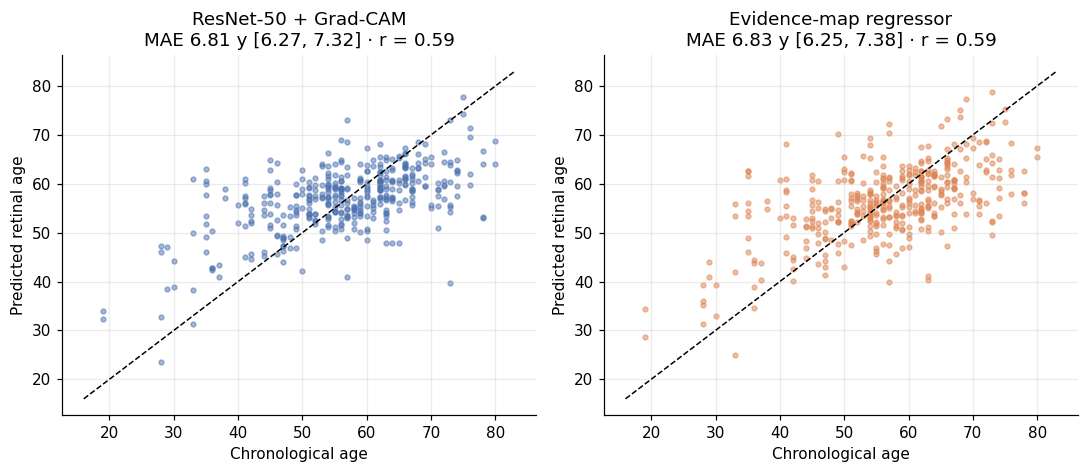

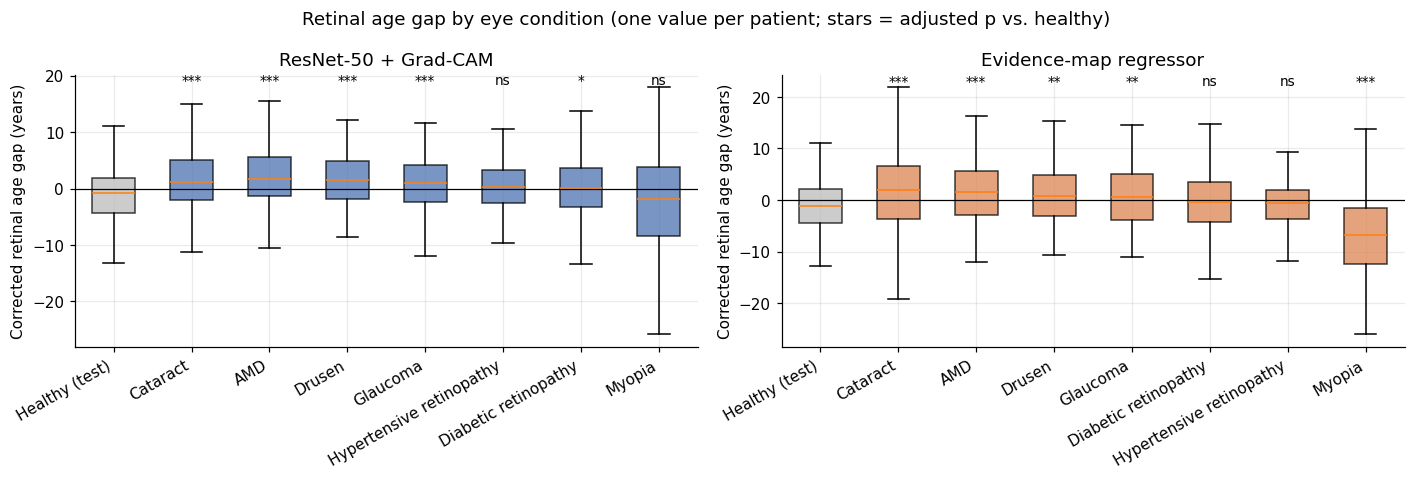

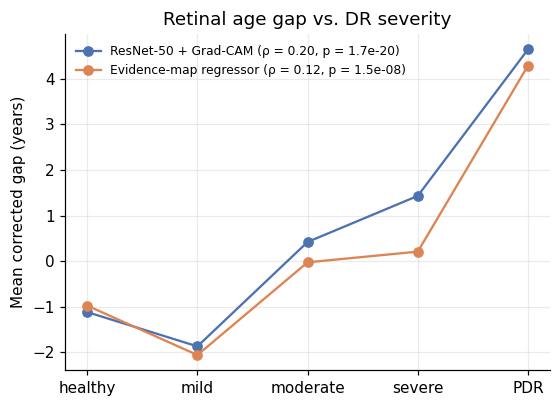

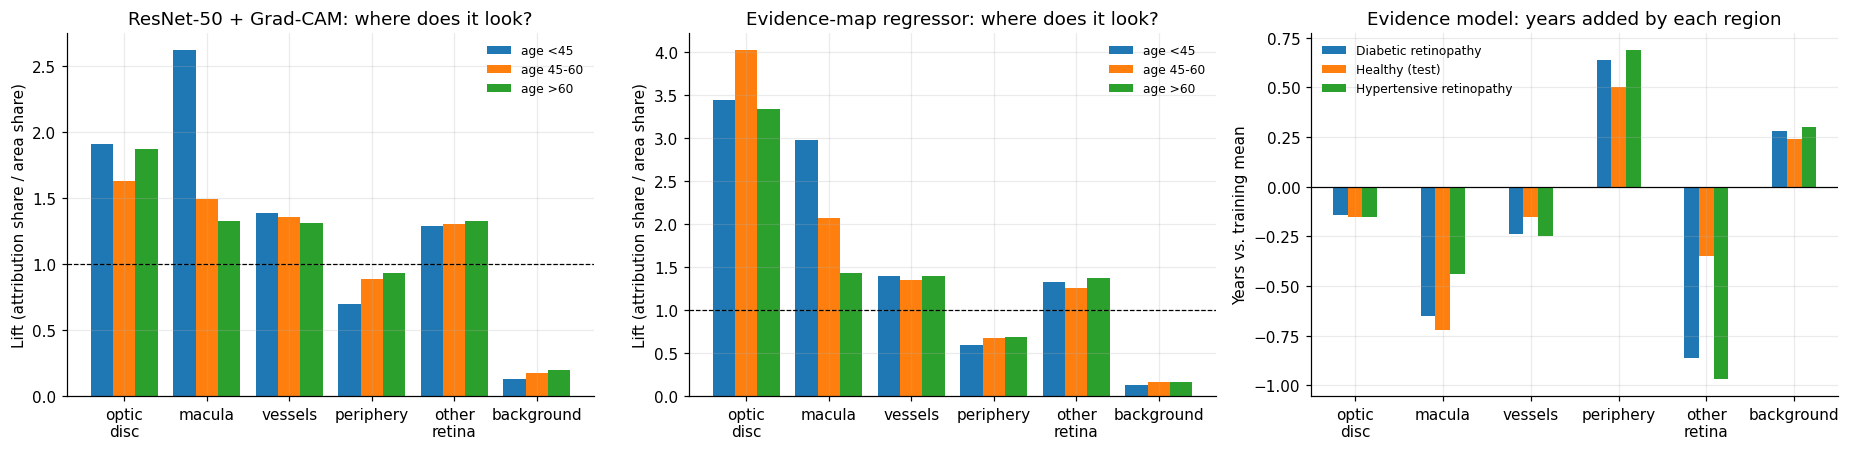

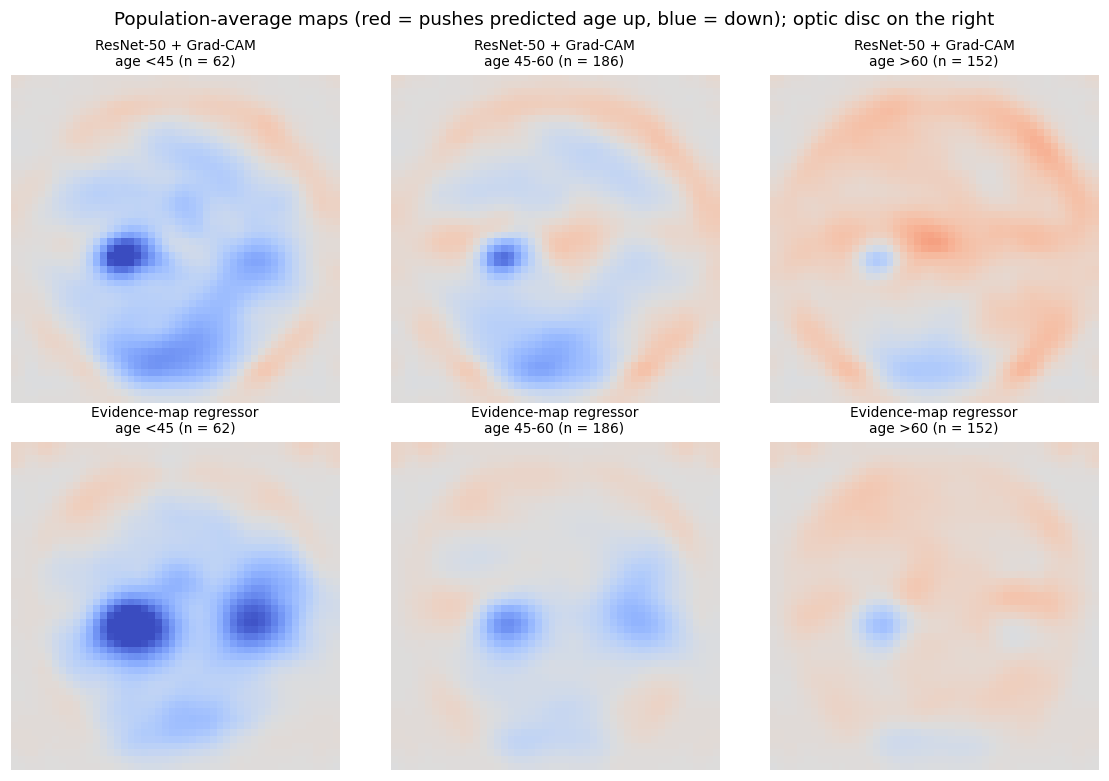

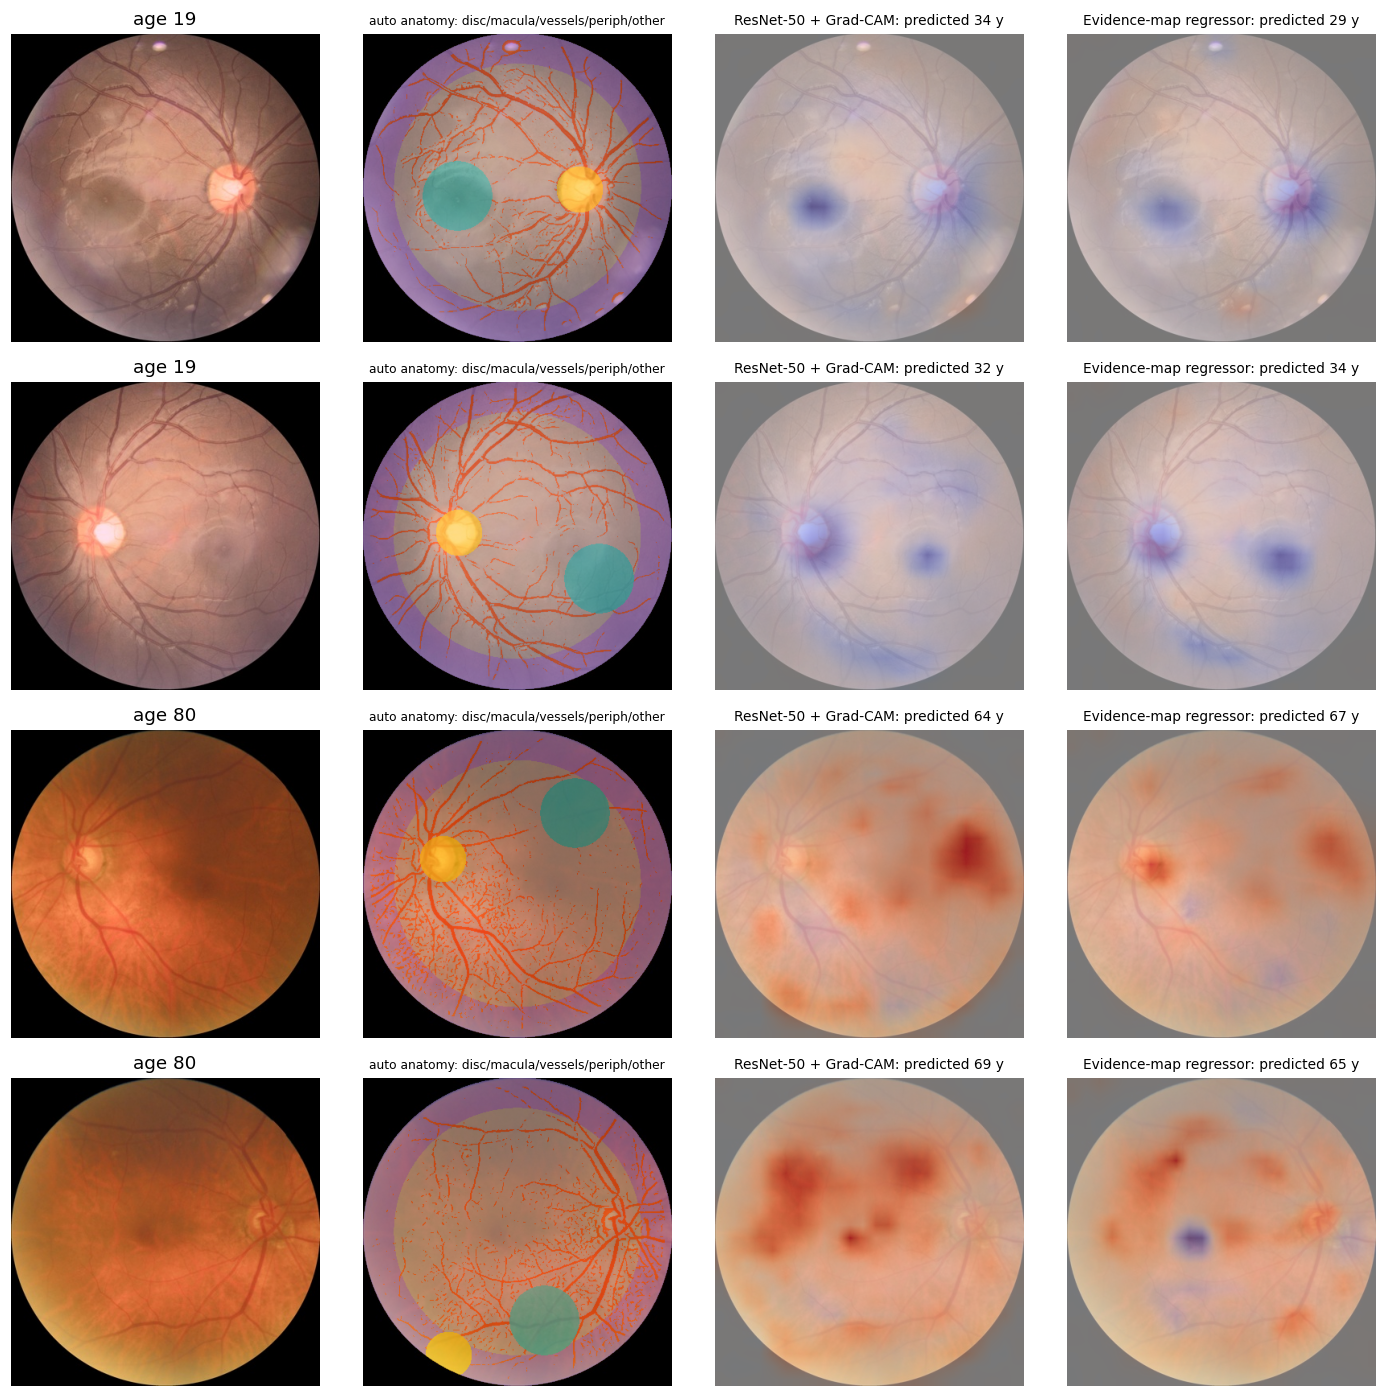

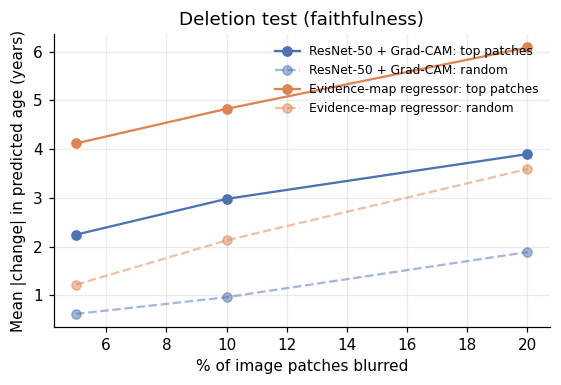

In [18]:
# --- Figures ---
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COL = {"gradcam": "#4C72B0", "evidence": "#DD8452"}

# 1) predicted vs. true age (healthy test)
fig, axes = plt.subplots(1, len(TRAINED), figsize=(5 * len(TRAINED), 4.4), squeeze=False)
for ax, kind in zip(axes[0], TRAINED):
    t = PRED[(kind, "test")]
    ax.scatter(t.age, t.pred, s=10, alpha=0.5, color=COL[kind])
    lim = [t.age.min() - 3, t.age.max() + 3]
    ax.plot(lim, lim, "k--", lw=1)
    r = ACC.set_index("model").loc[kind]
    ax.set_title(f"{NAME[kind]}\nMAE {r.MAE:.2f} y [{r.MAE_lo:.2f}, {r.MAE_hi:.2f}] · r = {r.pearson_r:.2f}")
    ax.set_xlabel("Chronological age"); ax.set_ylabel("Predicted retinal age")
fig.tight_layout(); fig.savefig(OUT / "fig1_age_prediction.png", bbox_inches="tight"); plt.show()

# 2) corrected age gap per group
fig, axes = plt.subplots(1, len(TRAINED), figsize=(6.5 * len(TRAINED), 4.4), squeeze=False)
for ax, kind in zip(axes[0], TRAINED):
    g = GAP_ROWS[GAP_ROWS.model == kind]
    order = ["Healthy (test)"] + [x for x in GAP_TABLE[GAP_TABLE.model == kind].group]
    data = [g[g.group == o].gap_corr.values for o in order]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55)
    for i, bx in enumerate(bp["boxes"]):
        bx.set_facecolor("#BBBBBB" if i == 0 else COL[kind]); bx.set_alpha(0.75)
    for i, o in enumerate(order[1:], start=2):
        p = GAP_TABLE[(GAP_TABLE.model == kind) & (GAP_TABLE.group == o)].adj_p.iloc[0]
        ax.text(i, ax.get_ylim()[1] * 0.92, "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns",
                ha="center", fontsize=9)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, rotation=30, ha="right")
    ax.set_ylabel("Corrected retinal age gap (years)"); ax.set_title(NAME[kind])
fig.suptitle("Retinal age gap by eye condition (one value per patient; stars = adjusted p vs. healthy)")
fig.tight_layout(); fig.savefig(OUT / "fig2_age_gap_by_group.png", bbox_inches="tight"); plt.show()

# 3) dose-response with DR severity
if len(SEV):
    fig, ax = plt.subplots(figsize=(5.2, 3.8))
    for kind in SEV.model:
        row = SEV[SEV.model == kind].iloc[0]
        ks = sorted(int(c.replace("mean_gap_sev", "")) for c in SEV.columns if c.startswith("mean_gap_sev") and not pd.isna(row[c]))
        ax.plot(ks, [row[f"mean_gap_sev{k}"] for k in ks], "-o", color=COL[kind],
                label=f"{NAME[kind]} (ρ = {row.spearman_rho:.2f}, p = {row.p:.1e})")
    ax.set_xticks(range(5)); ax.set_xticklabels(["healthy", "mild", "moderate", "severe", "PDR"])
    ax.set_ylabel("Mean corrected gap (years)"); ax.set_title("Retinal age gap vs. DR severity")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(OUT / "fig3_gap_vs_dr_severity.png", bbox_inches="tight"); plt.show()

# 4) region lift by age group + evidence-model years per region
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, kind in zip(axes[:2], TRAINED):
    s = REG_SUM.loc[kind] if kind in REG_SUM.index.get_level_values(0) else None
    if s is not None:
        xs = np.arange(len(REGIONS))
        for j, ag in enumerate(s.index):
            ax.bar(xs + (j - 1) * 0.27, s.loc[ag].values, 0.27, label=f"age {ag}")
        ax.axhline(1, color="k", lw=0.8, ls="--")
        ax.set_xticks(xs); ax.set_xticklabels([r.replace("_", "\n") for r in REGIONS])
        ax.set_title(f"{NAME[kind]}: where does it look?"); ax.set_ylabel("Lift (attribution share / area share)")
        ax.legend(frameon=False, fontsize=8)
yrs = YEARS.T
yrs.index = [i.replace("_years", "").replace("_", "\n") for i in yrs.index]
yrs.plot(kind="bar", ax=axes[2], rot=0)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_title("Evidence model: years added by each region"); axes[2].set_ylabel("Years vs. training mean")
axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig4_regions.png", bbox_inches="tight"); plt.show()

# 5) population-average maps by age group (optic disc aligned to the right)
ages = REG_H_DF.age.values
bins = pd.cut(ages, [0, 45, 60, 200], labels=["<45", "45-60", ">60"])
fig, axes = plt.subplots(len(TRAINED), 3, figsize=(10.5, 3.6 * len(TRAINED)), squeeze=False)
for rI, kind in enumerate(TRAINED):
    maps = POP_H[kind]
    if kind == "gradcam":
        maps = maps / (np.abs(maps).sum((1, 2), keepdims=True) + 1e-12)
    vmax = np.abs(maps.mean(0)).max() * 1.5 + 1e-12
    for c, ag in enumerate(["<45", "45-60", ">60"]):
        sel = np.asarray(bins == ag)
        ax = axes[rI, c]
        if sel.sum():
            im = ax.imshow(maps[sel].mean(0), cmap="coolwarm", vmin=-vmax, vmax=vmax)
        ax.set_title(f"{NAME[kind]}\nage {ag} (n = {int(sel.sum())})", fontsize=9)
        ax.axis("off"); ax.grid(False)
fig.suptitle("Population-average maps (red = pushes predicted age up, blue = down); optic disc on the right")
fig.tight_layout(); fig.savefig(OUT / "fig5_population_maps.png", bbox_inches="tight"); plt.show()

# 6) examples: anatomy masks + both maps (young vs. old)
ex = pd.concat([REG_H_DF.nsmallest(2, "age"), REG_H_DF.nlargest(2, "age")])
fig, axes = plt.subplots(len(ex), 4, figsize=(13, 3.2 * len(ex)), squeeze=False)
cmap_reg = matplotlib.colors.ListedColormap(["#FFD700", "#00CED1", "#FF4500", "#9370DB", "#A9A9A9"])
for rI, r in enumerate(ex.itertuples()):
    a = load_rgb(r.cpath)
    masks, odc, mac = anatomy_masks(a)
    lab = np.full(a.shape[:2], np.nan)
    for i, k in enumerate(REGIONS[:-1]):
        lab[masks[k]] = i
    axes[rI, 0].imshow(a); axes[rI, 0].set_title(f"age {r.age:.0f}")
    axes[rI, 1].imshow(a); axes[rI, 1].imshow(lab, cmap=cmap_reg, alpha=0.45, vmin=0, vmax=4)
    axes[rI, 1].set_title("auto anatomy: disc/macula/vessels/periph/other", fontsize=8)
    x = normalize(to_tensor(a)[None]).to(DEVICE)
    for c, kind in enumerate(TRAINED, start=2):
        p, m = explain(TRAINED[kind], x)
        m = m[0].float().cpu().numpy(); v = np.abs(m).max() + 1e-12
        axes[rI, c].imshow(a); axes[rI, c].imshow(m, cmap="coolwarm", vmin=-v, vmax=v, alpha=0.55)
        axes[rI, c].set_title(f"{NAME[kind]}: predicted {float(p[0]):.0f} y", fontsize=9)
for a_ in axes.ravel():
    a_.axis("off"); a_.grid(False)
fig.tight_layout(); fig.savefig(OUT / "fig6_examples.png", bbox_inches="tight"); plt.show()

# 7) deletion
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for kind in TRAINED:
    d = DEL_SUM.loc[kind]
    ax.plot(d.index * 100, d["top"], "-o", color=COL[kind], label=f"{NAME[kind]}: top patches")
    ax.plot(d.index * 100, d["random"], "--o", color=COL[kind], alpha=0.5, label=f"{NAME[kind]}: random")
ax.set_xlabel("% of image patches blurred"); ax.set_ylabel("Mean |change| in predicted age (years)")
ax.set_title("Deletion test (faithfulness)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig7_deletion.png", bbox_inches="tight"); plt.show()

In [19]:
# --- Auto-generated summary ---
def md_table(df):
    df = df.copy()
    out = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(out)

lines = [f"# Retinal age results{' (DEMO data)' if DEMO_MODE else ''}", "",
         f"Training: healthy patients only, patient-level split · image size {CFG['img_size']} px · "
         f"train age mean {AGE_MEAN:.1f} ± {AGE_STD:.1f}", "",
         "## Age prediction (healthy test)", md_table(ACC), "",
         "## Corrected retinal age gap vs. healthy", md_table(GAP_TABLE), ""]
if len(SEV):
    lines += ["## Gap vs. DR severity", md_table(SEV), ""]
lines += ["## Region lift by age group (healthy test)", md_table(REG_SUM.reset_index()), "",
          "## Evidence model: years per region", md_table(YEARS.reset_index()), ""]
if len(REGION_TESTS):
    lines += ["## Region contribution: disease vs. healthy", md_table(REGION_TESTS), ""]
lines += ["## Deletion test", md_table(DEL_SUM.reset_index()), ""]
notes = []
for kind in TRAINED:
    r = ACC.set_index("model").loc[kind]
    notes.append(f"- {NAME[kind]}: MAE {r.MAE:.2f} years on healthy test patients (r = {r.pearson_r:.2f}).")
    g = GAP_TABLE[GAP_TABLE.model == kind]
    for _, row in g.iterrows():
        notes.append(f"  {row.group}: adjusted gap {row.adj_diff_years:+.2f} years vs. healthy (p = {row.adj_p:.1e}, n = {row.n_patients}).")
lines += ["## Automatic notes (verify before writing anything)"] + notes
(OUT / "summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))
print("\nSaved all tables and figures to:", OUT)

# Retinal age results

Training: healthy patients only, patient-level split · image size 384 px · train age mean 56.8 ± 11.1

## Age prediction (healthy test)
| model | n_eyes | n_patients | MAE | MAE_lo | MAE_hi | pearson_r | R2 | bias_slope | bias_intercept |
|---|---|---|---|---|---|---|---|---|---|
| gradcam | 400 | 200 | 6.805 | 6.266 | 7.318 | 0.594 | 0.352 | -0.664 | 38.976 |
| evidence | 400 | 200 | 6.833 | 6.254 | 7.383 | 0.591 | 0.338 | -0.622 | 35.850 |

## Corrected retinal age gap vs. healthy
| model | group | n_patients | mean_gap | ci_lo | ci_hi | healthy_mean | cohens_d | mannwhitney_p | adj_diff_years | adj_p |
|---|---|---|---|---|---|---|---|---|---|---|
| evidence | Cataract | 196 | 2.078 | 0.716 | 3.384 | -0.975 | 0.388 | 0.000 | 4.442 | 0.000 |
| evidence | AMD | 162 | 1.275 | 0.369 | 2.162 | -0.975 | 0.389 | 0.000 | 2.695 | 0.000 |
| evidence | Drusen | 113 | 0.857 | -0.189 | 1.910 | -0.975 | 0.326 | 0.010 | 1.907 | 0.004 |
| evidence | Glaucoma | 201 | 0.766 | -

## How to read the results

- **Fig 1.** Published fundus age models trained on very large cohorts report MAEs of roughly 3 to 4 years. With a few thousand ODIR images, expect a clearly higher MAE. That is fine for a pilot; what matters is whether the gap carries signal.
- **Fig 2 / table "age gap".** A positive adjusted difference means eyes in that group look older than healthy eyes of the same age and sex. Hypertensive and diabetic retinopathy are the "systemic health" groups. Cataract is a useful sanity check: haze changes image appearance, so a gap there may reflect image quality more than biology.
- **Fig 3.** If the gap increases from mild to proliferative DR, that is a dose-response pattern, which is stronger evidence than a single group difference.
- **Fig 4, 5.** Lift > 1 means the model looks at a region more than its size suggests. The evidence model gives exact years per region, so you can say for example "vessels add X years in hypertensive eyes".
- **Fig 7.** If blurring the top-attributed patches changes the prediction more than random patches, the explanation is faithful.

## Limitations (state them honestly)

- ODIR "hypertensive retinopathy" and "diabetic retinopathy" are **eye findings**, not confirmed systemic diagnoses or blood pressure / HbA1c values. A full study needs cohort data with systemic measurements (for example UK Biobank or the German National Cohort).
- Disease eyes contain lesions the model never saw in training (healthy-only training), so part of the gap may be distribution shift. Comparing the region-level contributions helps separate "older-looking vessels" from "lesions confuse the model".
- The anatomy masks are automatic and approximate (brightest blob = disc, darkest spot = macula, Frangi = vessels). Check fig 6 visually.
- Single seed, single dataset (one country). Repeat with 3 seeds and an external dataset before drawing conclusions.

## Next steps

1. Replace the automatic masks with a vessel segmentation model and measure vessel calibre directly (artery/vein ratio).
2. Add a ViT or a retinal foundation model backbone.
3. With cohort data: relate the gap to blood pressure, HbA1c and mortality, and check whether the region-level contributions (e.g. vessels) explain that link.